# Checkpoint 2 

**Literature context (Nov 22, 2026).** Our current `matched_candidate` units are **putative optotagging candidates**, not validated Cre+ identities. The short evidence notes below are intended for discussion with Liz; full sources, methods, and open questions: [LITERATURE_REVIEW.md](LITERATURE_REVIEW.md). **No candidate thresholds or numerical results are changed in this checkpoint.**

## LED vs. laser optotagging

**Data and analysis setup**
Rates use the 8-ms evoked window after pulse onset and the saved matched-candidate and QC flags. Session IDs below 789848216 are labeled LED and IDs at or above it are labeled laser. Allen documents this session-ID cutoff as the LED-to-laser hardware transition, though delivered power and recording-era confounds remain. Reconnect `WD_BLACK` before running.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path(os.environ.get("SPIKES2SLOPE_DATA", "/Volumes/WD_BLACK/Spikes2Slope"))
SOURCE = ROOT / "opto_results" / "all_opto_unit_results.csv"
if not SOURCE.is_file():
    raise FileNotFoundError(f"Connect WD_BLACK or set SPIKES2SLOPE_DATA: {SOURCE}")
df = pd.read_csv(SOURCE)
required = {"unit_id", "ecephys_session_id", "cre_line", "evoked_rate_hz",
            "baseline_rate_hz", "n_pulses", "matched_candidate", "snr_qc"}
assert required.issubset(df.columns), f"Missing columns: {required - set(df.columns)}"
assert df.unit_id.is_unique, "Expected one row per unit"
for flag in ["matched_candidate", "snr_qc"]:
    df[flag] = df[flag].astype(str).str.lower().map(
        {"true": True, "false": False, "1": True, "0": False})
    assert df[flag].notna().all(), f"Unexpected values in {flag}"
df["hardware"] = np.where(df.ecephys_session_id < 789848216, "LED", "Laser")
order = ["LED", "Laser"]
colors = {"LED": "#0072B2", "Laser": "#D55E00"}
sns.set_theme(style="whitegrid", context="notebook")
eligible = df.loc[df.snr_qc].copy()
candidates = df.loc[df.matched_candidate].copy()
assert (candidates.snr_qc).all()
session = df.groupby(["ecephys_session_id", "hardware", "cre_line"], as_index=False).agg(
    eligible=("snr_qc", "sum"), candidates=("matched_candidate", "sum"),
    n_pulses=("n_pulses", "first"))
session["yield_pct"] = np.where(session.eligible > 0,
                                100 * session.candidates / session.eligible, np.nan)
means = candidates.groupby("ecephys_session_id").evoked_rate_hz.mean().rename("mean_evoked_hz")
session = session.merge(means, on="ecephys_session_id", how="left")
assert session.groupby("ecephys_session_id").size().eq(1).all()
print(f"{len(session)} sessions, {len(eligible):,} QC-eligible units, {len(candidates):,} candidates.")
print("Hardware assignment: inherited session-period proxy; not independently verified.")

28 sessions, 8,415 QC-eligible units, 1,127 candidates.
Hardware assignment: inherited session-period proxy; not independently verified.


**How many optotagging candidates did each group produce?**
Compare candidate counts and the fraction of QC-eligible units that met the candidate criteria.

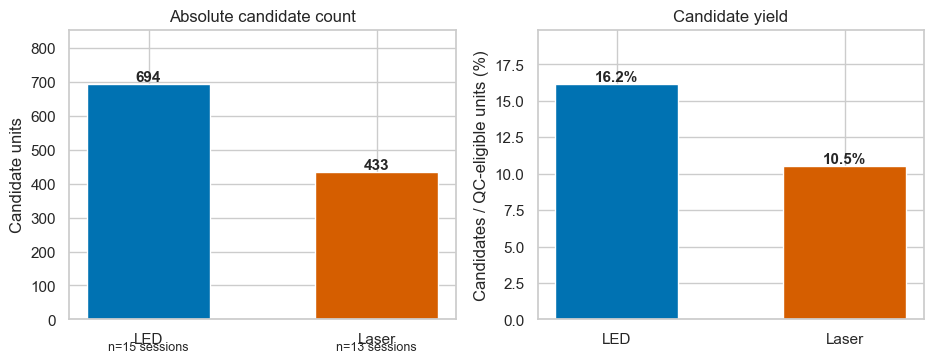

In [2]:
summary = session.groupby("hardware").agg(
    sessions=("ecephys_session_id", "size"),
    eligible=("eligible", "sum"), candidates=("candidates", "sum")).reindex(order)
summary["yield_pct"] = 100 * summary.candidates / summary.eligible
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, col, ylabel in zip(axes, ["candidates", "yield_pct"],
                            ["Candidate units", "Candidates / QC-eligible units (%)"]):
    vals = summary[col].to_numpy()
    ax.bar(order, vals, color=[colors[h] for h in order], width=.54)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.0f}" if col=="candidates" else f"{v:.1f}%",
                ha="center", va="bottom", fontsize=11, weight="bold")
    ax.set(ylabel=ylabel); ax.set_ylim(0, max(vals)*1.23)
axes[0].set_title("Absolute candidate count")
axes[1].set_title("Candidate yield")
for i,h in enumerate(order):
    axes[0].text(i, -max(summary.candidates)*.13, f"n={summary.loc[h,'sessions']} sessions",
                 ha="center", fontsize=9)
fig.tight_layout()
plt.show()

The LED-proxy group yielded **694 candidates across 15 sessions (16.2% of QC-eligible units)**. The laser-proxy group yielded **433 across 13 sessions (10.5%)**. These yields describe how often units passed the selection criteria.

**How do candidate firing-rate distributions compare?**
Bars show the percentage of candidates within each hardware-proxy group in each 8-ms evoked firing-rate bin.

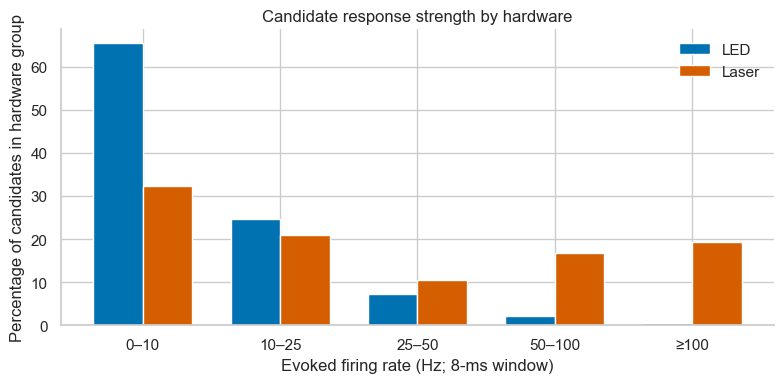

In [3]:
bins = [0, 10, 25, 50, 100, np.inf]
labels = ["0–10", "10–25", "25–50", "50–100", "≥100"]
rate_bins = candidates.assign(rate_bin=pd.cut(candidates.evoked_rate_hz,
                                              bins=bins, labels=labels, right=False))
rate_pct = (pd.crosstab(rate_bins.hardware, rate_bins.rate_bin, normalize="index")
              .reindex(index=order, columns=labels, fill_value=0) * 100)
x = np.arange(len(labels))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4))
for j,h in enumerate(order):
    bars = ax.bar(x + (j-0.5)*width, rate_pct.loc[h], width, label=h, color=colors[h])
ax.set_xticks(x, labels)
ax.set(xlabel="Evoked firing rate (Hz; 8-ms window)",
       ylabel="Percentage of candidates in hardware group",
       title="Candidate response strength by hardware")
ax.legend(frameon=False)
sns.despine()
fig.tight_layout()
plt.show()

The pooled candidate median was **5.56 Hz for LED** and **21.67 Hz for laser**. These distributions describe individual candidates, which are nested within recording sessions.

**Is the session-level firing-rate difference statistically supported?**
Each point is a session mean across candidates. Diamonds show the group means and whiskers show 95% confidence intervals. Welch compares arithmetic means, and Mann–Whitney compares rank distributions.

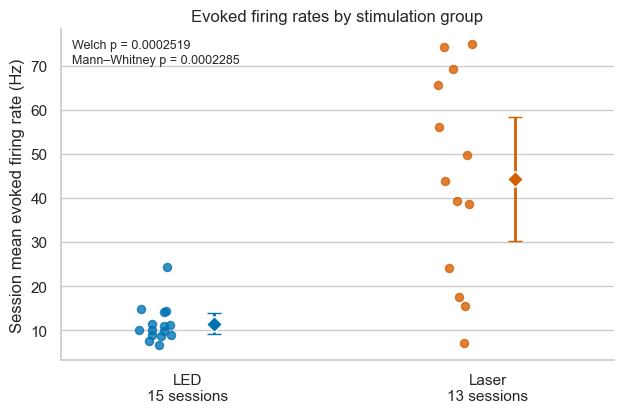

In [4]:
rate_sessions = session.dropna(subset=["mean_evoked_hz"]).copy()
rate_groups = {h: rate_sessions.loc[rate_sessions.hardware.eq(h), "mean_evoked_hz"]
               for h in order}

s = session.dropna(subset=["mean_evoked_hz"]).copy()
a = s.loc[s.hardware.eq("LED"), "mean_evoked_hz"].to_numpy()
b = s.loc[s.hardware.eq("Laser"), "mean_evoked_hz"].to_numpy()
test = stats.ttest_ind(a, b, equal_var=False)

def welch_session_comparison(led, laser, result=None):
    led, laser = np.asarray(led), np.asarray(laser)
    difference = led.mean() - laser.mean()
    v_led = led.var(ddof=1) / len(led)
    v_laser = laser.var(ddof=1) / len(laser)
    dof = (v_led + v_laser)**2 / (
        v_led**2 / (len(led) - 1) + v_laser**2 / (len(laser) - 1))
    margin = stats.t.ppf(.975, dof) * np.sqrt(v_led + v_laser)
    if result is None:
        result = stats.ttest_ind(led, laser, equal_var=False)
    return {"difference_hz": difference, "ci_low_hz": difference - margin,
            "ci_high_hz": difference + margin, "df": dof,
            "t": result.statistic, "p": result.pvalue}


led_rates, laser_rates = (rate_groups[h] for h in order)
welch_rates = welch_session_comparison(led_rates, laser_rates, result=test)
rank_rates = stats.mannwhitneyu(led_rates, laser_rates, alternative="two-sided",
                               method="asymptotic")
def plot_session_rates(ax, rows, rng):
    for i, h in enumerate(order):
        values = rows.loc[rows.hardware.eq(h), "mean_evoked_hz"]
        ax.scatter(i + rng.uniform(-.17, -.05, len(values)), values,
                   color=colors[h], s=34, alpha=.78)
        if len(values) >= 2:
            margin = stats.t.ppf(.975, len(values) - 1) * stats.sem(values)
            ax.errorbar(i + .09, values.mean(), yerr=margin, fmt="D", color=colors[h],
                        markeredgecolor="white", markersize=8, capsize=5, linewidth=2)
        elif len(values) == 1:
            ax.plot(i + .09, values.iloc[0], marker="D", color=colors[h])
    counts = rows["hardware"].value_counts()
    ax.set_xticks(range(len(order)), [f"{h}\n{counts.get(h, 0)} sessions" for h in order])
    ax.set(xlim=(-.42, 1.42))
    ax.grid(axis="x", visible=False)


fig, ax = plt.subplots(figsize=(6.4, 4.3))
plot_session_rates(ax, rate_sessions, np.random.default_rng(42))
ax.set(ylabel="Session mean evoked firing rate (Hz)",
       title="Evoked firing rates by stimulation group")
ax.text(.02, .97, f"Welch p = {welch_rates['p']:.4g}\nMann–Whitney p = {rank_rates.pvalue:.4g}",
        transform=ax.transAxes, va="top", fontsize=9)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

Across 15 LED-proxy and 13 laser-proxy sessions, the **Welch mean difference was −32.83 Hz** (LED minus laser, 95% CI −47.00 to −18.67, *p* = 0.000252). **Mann–Whitney U = 17** (*p* = 0.000228) supports a rank-distribution difference. The groups’ different spreads limit a median-shift interpretation.

**How common are weak optotagging responses?**
Austin’s comparison uses two definitions: exactly one evoked spike and zero baseline spikes across all presentations, and an exploratory threshold of at most 0.1 mean evoked spike per pulse.

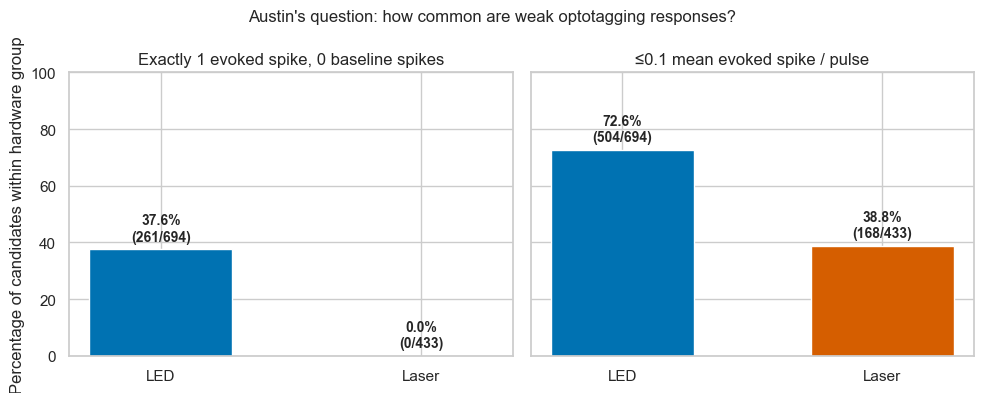

In [5]:
WINDOW_S = 0.008
# Counts are reconstructed from aggregate rates and presentation counts.
# The original processing uses 8-ms baseline and evoked windows.
candidates = candidates.copy()
candidates["evoked_total"] = np.rint(candidates.evoked_rate_hz * candidates.n_pulses * WINDOW_S).astype(int)
candidates["baseline_total"] = np.rint(candidates.baseline_rate_hz * candidates.n_pulses * WINDOW_S).astype(int)
candidates["exact_one_zero"] = (candidates.evoked_total == 1) & (candidates.baseline_total == 0)
candidates["mean_spikes_per_pulse"] = candidates.evoked_rate_hz * WINDOW_S
THRESH = 0.10  # Exploratory, NOT a validated candidate exclusion criterion
candidates["weak_per_pulse"] = candidates.mean_spikes_per_pulse <= THRESH

def summarize(flag):
    result = candidates.groupby("hardware").agg(
        total=("unit_id", "size"), matching=(flag, "sum")).reindex(order)
    result["pct"] = 100 * result.matching / result.total
    return result
exact = summarize("exact_one_zero")
comparable = summarize("weak_per_pulse")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0), sharey=True)
panels = [
    ("Exactly 1 evoked spike, 0 baseline spikes", exact),
    ("≤0.1 mean evoked spike / pulse", comparable)
]
for ax, (ttl, dat) in zip(axes, panels):
    ax.bar(order, dat.pct, width=.55, color=[colors[h] for h in order])
    for j,h in enumerate(order):
        row = dat.loc[h]
        ax.text(j, row.pct + 2, f"{row.pct:.1f}%\n({int(row.matching)}/{int(row.total)})",
                ha="center", va="bottom", fontsize=10, weight="bold")
    ax.set(title=ttl, xlabel="", ylim=(0, 100))
axes[0].set_ylabel("Percentage of candidates within hardware group")
fig.suptitle("Austin's question: how common are weak optotagging responses?", fontsize=12)
fig.tight_layout()
plt.show()

The exact pattern occurred in **261/694 LED candidates (37.6%)** and **0/433 laser candidates**, because the longer laser-proxy protocols make one spike insufficient to pass the response threshold. With the per-pulse threshold, **72.6% of LED candidates and 38.8% of laser candidates** fell in the weak-response range. This exploratory threshold describes response strength among selected candidates.

**Literature check — does one light-window spike count as tagged?** Allen's [Visual Coding optotagging tutorial](https://allensdk.readthedocs.io/en/stable/_static/examples/nb/ecephys_optotagging.html) says, “We can select a threshold, such as 2x increase in firing rate” (Identifying Cre+ units). That is an **illustrative rate-ratio screen**, not proof that a unit's spikes are reproducibly driven by light. In contrast, [Wei et al. (2023)](https://doi.org/10.1038/s41467-023-37844-8) used an evoked rate **>25 Hz** and **>2.5×** baseline (2–8 ms window). Other protocols examine short latency, trial reliability, and light-locked responses. **For Liz:** Keep our present flag as a candidate screen; do not automatically retain or reject single-spike units as validated tags. First inspect pulse-resolved rasters/PSTHs, artifact windows, non-light baselines, and per-pulse response probability. One evoked spike across 45 presentations is only ~2.2% of presentations, assuming one spike total. **Threshold decision remains open.**

**Does the firing-rate difference persist after accounting for Cre line?**
The table shows how many sessions contributed to each Cre-line-supported candidate population. Yield is the percentage of QC-eligible units that met the candidate criteria, and rates give each contributing recording equal weight.

In [6]:
cre_order = ["Pvalb", "Sst", "Vip"]
cre_index = pd.MultiIndex.from_product([cre_order, order], names=["cre_line", "hardware"])
composition = session.groupby(["cre_line", "hardware"]).agg(
    sessions=("ecephys_session_id", "size"), eligible_units=("eligible", "sum"),
    candidate_units=("candidates", "sum"), session_mean_hz=("mean_evoked_hz", "mean"))
composition = composition.reindex(cre_index)
count_cols = ["sessions", "eligible_units", "candidate_units"]
composition[count_cols] = composition[count_cols].fillna(0).astype(int)
composition["yield_pct"] = (100 * composition["candidate_units"]
                            / composition["eligible_units"].replace(0, np.nan))
unit_rates = candidates.groupby(["cre_line", "hardware"])["evoked_rate_hz"].agg(
    unit_mean_hz="mean", unit_median_hz="median")
cre_composition_full = composition.join(unit_rates)
display(cre_composition_full[["sessions", "yield_pct", "session_mean_hz"]].rename(
    columns={"sessions": "Sessions", "yield_pct": "Candidate yield (%)",
             "session_mean_hz": "Mean session rate (Hz)"}).round(2))

Sessions  Candidate yield (%)  Mean session rate (Hz)
cre_line hardware                                                       
Pvalb    LED              4                13.97                   13.62
         Laser            4                17.55                   64.86
Sst      LED              8                17.25                   11.34
         Laser            4                 9.77                   53.17
Vip      LED              3                15.71                    8.82
         Laser            5                 5.94                   20.70

**Evoked firing rates within each Cre line**
Within Pvalb, Sst, and Vip candidate populations, compare session means on a shared vertical scale. Diamonds and whiskers show group means and 95% confidence intervals.

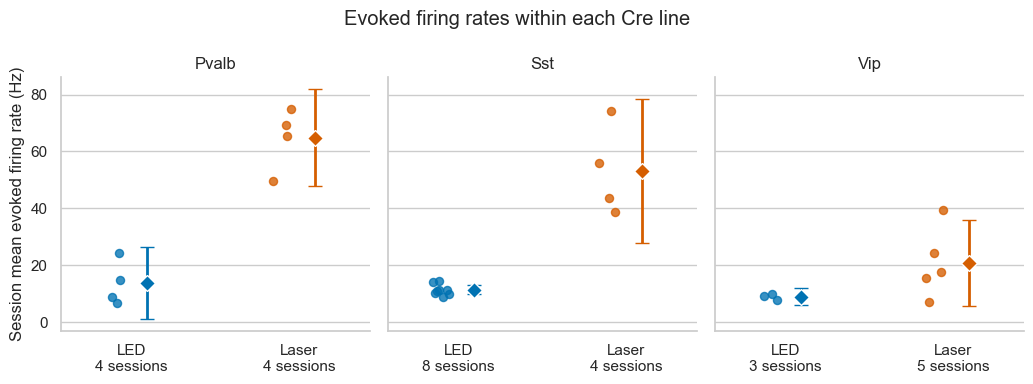

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.9), sharey=True)
cre_rng = np.random.default_rng(42)
for ax, cre in zip(axes, cre_order):
    plot_session_rates(ax, rate_sessions.loc[rate_sessions.cre_line.eq(cre)], cre_rng)
    ax.set_title(cre)
axes[0].set_ylabel("Session mean evoked firing rate (Hz)")
fig.suptitle("Evoked firing rates within each Cre line")
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

Laser-proxy session means were higher in all three Cre-line-supported candidate populations. The Vip contrast was smaller, and its exploratory 95% interval included zero. The small strata limit comparisons among Cre lines.

**Supporting checks (optional; hidden by default)**
The audit, session distribution diagnostics, leave-one-session-out tests, protocol checks, and Cre-line-adjusted regression still run and retain their variables, but verbose outputs are captured to keep the meeting walkthrough focused on the five figures. To inspect these outputs interactively, run `support_audit.show()`, `support_sensitivity.show()`, or `support_regression.show()` in a new cell. The main results are summarized in adjacent interpretations.


In [ ]:
%%capture support_audit
# Upstream evoked window: +1 to +9 ms. Baseline window: −10 to −2 ms.
# Rates are mean spikes per pulse divided by 0.008 s. Audit saved flags.
saved_flag = df["candidate_tagged"].astype(str).str.lower().isin(["true", "1"])
response_pass = df["evoked_rate_hz"].div(df["baseline_rate_hz"] + 1).gt(2)
qc_pass = (df["presence_ratio"].ge(.95) & df["isi_violations"].le(.5)
           & df["amplitude_cutoff"].le(.1) & df["snr"].ge(1))
assert saved_flag.equals(response_pass)
assert df["snr_qc"].equals(qc_pass)
assert df["matched_candidate"].equals(response_pass & qc_pass)

session_fields = ["specimen_id", "cre_line", "n_pulses"]
assert df.groupby("ecephys_session_id")[session_fields].nunique(dropna=False).eq(1).all().all()
specimens = df.groupby("ecephys_session_id")["specimen_id"].first()
assert specimens.notna().all() and specimens.is_unique
print(f"Candidate rates available for {len(rate_sessions)}/{len(session)} sessions.")
print(f"{len(specimens)} distinct specimens across {len(session)} recording sessions.")

rate_description = rate_sessions.groupby("hardware")["mean_evoked_hz"].agg(
    n="size", mean="mean", sd="std", median="median", minimum="min",
    maximum="max", skew="skew").reindex(order)
rate_description["iqr"] = rate_sessions.groupby("hardware")["mean_evoked_hz"].agg(
    lambda rates: rates.quantile(.75) - rates.quantile(.25))
print("\nSession mean rates (Hz) and sample skewness")
print(rate_description.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.5))
rate_bins_shared = np.histogram_bin_edges(rate_sessions["mean_evoked_hz"], bins=8)
for h, ax in zip(order, axes[1:]):
    values = rate_groups[h]
    axes[0].hist(values, bins=rate_bins_shared, histtype="stepfilled",
                 color=colors[h], alpha=.45, label=f"{h} (n={len(values)})")
    (quantiles, ordered), (slope, intercept, _) = stats.probplot(values, dist="norm")
    ax.scatter(quantiles, ordered, color=colors[h], s=26)
    ax.plot(quantiles, intercept + slope * quantiles, color="0.45", linewidth=1)
    ax.set(title=f"{h} normal Q–Q (n={len(values)})", xlabel="Theoretical quantiles",
           ylim=(0, 1.08 * rate_sessions["mean_evoked_hz"].max()))
axes[0].set(title="Session rate distributions", xlabel="Session mean rate (Hz)",
            ylabel="Recording sessions")
axes[0].legend(frameon=False)
axes[1].set_ylabel("Session mean rate (Hz)")
axes[2].tick_params(labelleft=False)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()
print("Welch comparison (LED − laser)")
print(pd.Series(welch_rates).to_string(float_format=lambda value: f"{value:.7g}"))
print(f"\nMann–Whitney U (LED group) = {rank_rates.statistic:g}, p = {rank_rates.pvalue:.7g}")

In [ ]:
%%capture support_sensitivity
def compare_session_subset(rows):
    return welch_session_comparison(
        rows.loc[rows.hardware.eq("LED"), "mean_evoked_hz"],
        rows.loc[rows.hardware.eq("Laser"), "mean_evoked_hz"],
    )


leave_one_out = pd.DataFrame({
    sid: compare_session_subset(rate_sessions.loc[rate_sessions.ecephys_session_id.ne(sid)])
    for sid in rate_sessions["ecephys_session_id"]
}).T.rename_axis("omitted_session")
print("Leave-one-session-out ranges")
print(leave_one_out[["difference_hz", "ci_high_hz", "p"]].agg(["min", "max"]).to_string())
most_influential = leave_one_out["difference_hz"].sub(welch_rates["difference_hz"]).abs().idxmax()
print(f"Largest shift in the mean difference after omitting session {most_influential}.")

top_laser = rate_sessions.loc[rate_sessions.hardware.eq("Laser")].nlargest(2, "mean_evoked_hz")
trimmed_welch = compare_session_subset(rate_sessions.drop(top_laser.index))
print(f"\nOmit the two highest-rate laser sessions ({', '.join(top_laser.ecephys_session_id.astype(str))})")
print(pd.Series(trimmed_welch).to_string(float_format=lambda value: f"{value:.7g}"))

count_rows = []
for h, group in rate_sessions.groupby("hardware", sort=False):
    count_rows.append({
        "hardware": h,
        "candidate_min": group["candidates"].min(),
        "candidate_median": group["candidates"].median(),
        "candidate_max": group["candidates"].max(),
        "equal_session_mean_hz": group["mean_evoked_hz"].mean(),
        "candidate_weighted_mean_hz": np.average(group["mean_evoked_hz"], weights=group["candidates"]),
        "count_rate_spearman_rho": stats.spearmanr(group["candidates"], group["mean_evoked_hz"]).statistic,
    })
print("\nCandidate counts and descriptive weighting sensitivity")
print(pd.DataFrame(count_rows).set_index("hardware").reindex(order).round(3).to_string())

print("\nNumber of sessions by stimulation presentation count")
print(pd.crosstab(rate_sessions.hardware, rate_sessions.n_pulses).reindex(order).to_string())

protocol = pd.read_csv(ROOT / "opto_protocol_summary.csv")
protocol_by_hardware = rate_sessions.merge(
    protocol, on=["ecephys_session_id", "cre_line"], how="left", validate="one_to_one")
assert protocol_by_hardware["ten_ms_pulses"].eq(protocol_by_hardware["n_pulses"]).all()
print("\nSession counts by saved light-level settings (calibration unresolved)")
print(pd.crosstab(protocol_by_hardware.hardware, protocol_by_hardware.light_levels).reindex(order).to_string())

In [ ]:
%%capture support_regression
import statsmodels.formula.api as smf

print(cre_composition_full.round(3).to_string())

cre_overlap = (pd.crosstab(rate_sessions["cre_line"], rate_sessions["hardware"])
               .reindex(index=cre_order, columns=order, fill_value=0))
print("\nSessions with candidate rates by Cre line")
print(cre_overlap.to_string())
assert cre_overlap.gt(0).all().all(), "A Cre line lacks hardware overlap"
model = smf.ols(
    'mean_evoked_hz ~ C(hardware, Treatment(reference="Laser"))'
    ' + C(cre_line, Treatment(reference="Pvalb"))',
    data=rate_sessions,
)
assert len(model.endog) == len(rate_sessions)
model_rank = np.linalg.matrix_rank(model.exog)
assert model_rank == model.exog.shape[1], "The model design is rank deficient"
adjusted = model.fit(cov_type="HC3", use_t=True)
hardware_term = 'C(hardware, Treatment(reference="Laser"))[T.LED]'
adjusted_difference = adjusted.params[hardware_term]
ci_low, ci_high = adjusted.conf_int().loc[hardware_term]
print(f"\nEqual-session OLS with HC3 SEs (n={int(adjusted.nobs)}, design rank={model_rank}, "
      f"residual df={adjusted.df_resid:g})")
print(f"LED − laser adjusted for Cre line: {adjusted_difference:.4f} Hz "
      f"(95% CI {ci_low:.4f} to {ci_high:.4f}, p={adjusted.pvalues[hardware_term]:.7g})")
print(f"Adjusted minus unadjusted contrast: {adjusted_difference - welch_rates['difference_hz']:+.4f} Hz")

within_cre = pd.DataFrame({
    cre: compare_session_subset(rows)
    for cre, rows in rate_sessions.groupby("cre_line")
    if cre_overlap.loc[cre].ge(3).all()
}).T.reindex(cre_order)
print("\nExploratory within-Cre differences (LED − laser, unadjusted 95% CIs)")
print(within_cre.reindex(columns=["difference_hz", "ci_low_hz", "ci_high_hz"]).round(3).to_string())

**Interpretation for Liz and Austin**
Laser-proxy sessions had higher observed evoked firing rates among matched candidates. The LED-minus-laser difference remained negative after every single-session omission and after omitting the two highest-rate laser sessions. Cre-line adjustment gave **−36.12 Hz** (HC3 95% CI −48.21 to −24.03), close to the unadjusted **−32.83 Hz**.

Allen documents the hardware-period cutoff, but the delivered power is not matched, and adjustment leaves recording era, optical power, stimulation settings, and response-based candidate selection unresolved. The association provides insufficient evidence about causal hardware effects or biological tagging validity to justify excluding either group.

## Optotagging response validation

A single spike in the pooled evoked window can pass the AllenSDK tutorial’s rate-ratio screen when the baseline is silent and there are few presentations. It supplies one observation of the spike’s timing and cannot establish trial-to-trial reproducibility. Published approaches combine response elevation with evidence such as latency, jitter, repeated responses, or an artifact-trimmed rate floor. Criteria depend on the stimulation protocol. [Literature review, section 1](LITERATURE_REVIEW.md#1-what-counts-as-optotagged)

We align the original spike timestamps to the same pulse onsets used by the screen and compare the probability of one or more spikes in equal-duration light-on and light-off windows.

In [2]:
%%capture opto_audit_output
import h5py

opto_cache = ROOT / "allen_visual_coding_data"
opto_baseline = (-0.010, -0.002)
opto_evoked = (0.001, 0.009)
opto_control = (-0.110, -0.102)
opto_width_s = 0.008
opto_guard_s = 0.100  # Flag any baseline beginning <100 ms after an optical epoch.


def opto_nwb_path(session_id):
    return opto_cache / f"session_{session_id}" / f"session_{session_id}.nwb"


def opto_read_epochs(nwb):
    # This NWB table is the source of AllenSDK's optogenetic_stimulation_epochs.
    table = nwb["processing/optotagging/optogenetic_stimulation"]
    return pd.DataFrame({
        "epoch_id": table["id"][:],
        **{name: table[name].asstr()[:] for name in ("stimulus_name", "condition")},
        **{name: table[name][:] for name in ("start_time", "stop_time", "duration", "level")},
    }).sort_values("start_time", kind="stable").reset_index(drop=True)


def opto_window_overlap(starts, stops, other_starts, other_stops):
    # Half-open intervals. Check every epoch, including long ramps and pulse trains.
    return ((starts[:, None] < other_stops) & (stops[:, None] > other_starts)).any(axis=1)


opto_metadata = df[["ecephys_session_id", "cre_line", "hardware", "n_pulses"]].drop_duplicates()
assert opto_metadata.ecephys_session_id.is_unique
opto_epochs_by_session, opto_pulses_by_session = {}, {}
opto_audit_rows = []
for record in opto_metadata.sort_values("ecephys_session_id").itertuples(index=False):
    sid = record.ecephys_session_id
    with h5py.File(opto_nwb_path(sid), "r") as nwb:
        epochs = opto_read_epochs(nwb)
        # Check the controls occur after the last recorded visual/spontaneous presentation.
        last_presentation = max(
            group["stop_time"][:].max() for name, group in nwb["intervals"].items()
            if name.endswith("_presentations") and len(group["stop_time"])
        )
        invalid = nwb.get("intervals/invalid_times")
        invalid_start = invalid["start_time"][:] if invalid is not None else np.array([])
        invalid_stop = invalid["stop_time"][:] if invalid is not None else np.array([])

    starts, stops = epochs.start_time.to_numpy(), epochs.stop_time.to_numpy()
    assert np.isfinite(starts).all() and np.isfinite(stops).all() and (stops > starts).all()
    # Reproduce optotagcheck.ipynb's exact selection on the stored duration.
    pulses = epochs.loc[epochs.stimulus_name.eq("pulse")
                        & epochs.duration.between(0.009, 0.020, inclusive="neither")].copy()
    assert len(pulses) == record.n_pulses > 0, f"Pulse count mismatch in {sid}"
    on = pulses.start_time.to_numpy()
    off = pulses.stop_time.to_numpy()
    preceding = np.r_[-np.inf, np.maximum.accumulate(stops)[:-1]][pulses.index]
    baseline_gap = (on + opto_baseline[0]) - preceding
    control_gap = (on + opto_control[0]) - preceding
    baseline_overlap = opto_window_overlap(on + opto_baseline[0], on + opto_baseline[1],
                                           starts, stops)
    control_overlap = opto_window_overlap(on + opto_control[0], on + opto_control[1],
                                          starts, stops)
    on_light = (on + opto_evoked[0] >= on) & (on + opto_evoked[1] <= off)
    # Conservatively flag all windows crossing a marked invalid interval on any probe.
    invalid_pair = opto_window_overlap(on + opto_control[0], on + opto_evoked[1],
                                       invalid_start, invalid_stop)
    pulses["clean_pair"] = (on_light & ~baseline_overlap & ~control_overlap
                            & (baseline_gap >= opto_guard_s) & (control_gap >= opto_guard_s)
                            & (on + opto_control[0] >= last_presentation) & ~invalid_pair)
    opto_epochs_by_session[sid] = epochs
    opto_pulses_by_session[sid] = pulses
    inter_epoch_gap = starts[1:] - np.maximum.accumulate(stops)[:-1]
    opto_audit_rows.append({
        "session": sid, "Cre": record.cre_line, "period": record.hardware,
        "epochs": len(epochs), "pulses": len(pulses),
        "level counts": pulses.groupby("level").size().to_dict(),
        "min pulse ms": 1000 * (off - on).min(),
        "max pulse ms": 1000 * (off - on).max(),
        "evoked outside pulse": int((~on_light).sum()),
        "min inter-epoch gap (s)": inter_epoch_gap.min(),
        "max inter-epoch gap (s)": inter_epoch_gap.max(),
        "min baseline gap (s)": baseline_gap.min(),
        "min control gap (s)": control_gap.min(),
        "baseline overlaps": int(baseline_overlap.sum()),
        "baseline within 100 ms": int((baseline_gap < opto_guard_s).sum()),
        "control overlaps": int(control_overlap.sum()),
        "control within 100 ms": int((control_gap < opto_guard_s).sum()),
        "control overlaps visual block": int((on + opto_control[0] < last_presentation).sum()),
        "invalid pairs": int(invalid_pair.sum()),
        "clean pairs": int(pulses.clean_pair.sum()),
    })

opto_timing = pd.DataFrame(opto_audit_rows).set_index("session")
opto_conditions = (
    pd.concat(opto_epochs_by_session, names=["session", "row"]).reset_index()
    .assign(nominal_ms=lambda rows: (1000 * rows.duration).round(3))
    .groupby(["session", "stimulus_name", "condition", "nominal_ms", "level"])
    .size().rename("presentations")
)
display(opto_timing, opto_conditions)

### Verified timing in the local cache

- **28 sessions and 1,726 analysis presentations.** We reproduced the original filter (`pulse`, recorded duration strictly between 9 and 20 ms). Every selected presentation was a single square pulse with a 10.000 ms onset-to-offset duration at the precision shown. Other cached epochs were 5 ms square pulses, 1 s half-cosine ramps and 1 s trains of 2.5 ms pulses at 10 Hz. The onset, offset, nominal duration and recorded condition are retained per epoch in `opto_epochs_by_session`.
- **Pulse counts and levels varied.** The 15 LED-period sessions had 45 analysis pulses of 180 total epochs each, with 15 repeats at each recorded level (1, 2.5, 4). Twelve laser-period sessions had 75 of 300 epochs with 25 repeats per level. Most used 1.3, 1.7 and 2.0. Sessions 839068429 and 840012044 used 0.6375, 0.7375 and 0.82. Laser-period Vip session 816200189 had 151 of 609 epochs with 50, 50 and 51 repeats at 1.3, 1.7 and 2.0, and a gap of about 110 s between two optical epochs. Period and level come from the session-ID proxy and stored protocol values, respectively.
- **Both 8 ms windows fit the protocol.** The baseline [−10, −2) ms overlapped zero optical epochs and began at least 670 ms after a preceding optical epoch wherever one existed. The earlier light-off control [−110, −102) ms also had zero overlaps and at least 570 ms of clearance. Both fall after the recorded visual/spontaneous blocks. A marked invalid interval in session 721123822 spans 11 paired windows under the conservative any-probe check. All trials in the four plotted sessions passed these checks.
- **Artifact risk remains.** The evoked window [+1, +9) ms lies entirely inside every selected pulse and leaves 1 ms at each edge. The guard is a timing convention. Counts within ±1 ms of each actual edge and a [+2, +8) ms sensitivity window show how much the examples depend on near-edge detections. Sorted spike timestamps alone cannot establish the electrical origin of an edge transient.

### Representative candidates

Use one saved `matched_candidate` per response band. The bands use pooled screen results and serve only to sample the range of responses. “Single spike” means exactly one evoked spike across all analysis pulses, “Low” means two or more spikes and <10 Hz, “Moderate” covers 10 to <50 Hz, and “High” covers ≥50 Hz. A seed of 42 draws from unit IDs in sorted order, prioritizing Cre lines and then hardware periods and sessions absent from the sample so far. The saved rates identify the sampling bands. Every displayed count is recomputed from timestamps with the screen’s half-open windows and checked against the corresponding saved rate.

In [3]:
%%capture opto_trial_output
opto_pool = candidates.sort_values("unit_id").copy()
opto_pool["screen_evoked_count"] = np.rint(
    opto_pool.evoked_rate_hz * opto_pool.n_pulses * opto_width_s
).astype(int)
opto_pool["band"] = np.select(
    [opto_pool.screen_evoked_count.eq(1), opto_pool.evoked_rate_hz.lt(10),
     opto_pool.evoked_rate_hz.lt(50)],
    ["Single spike", "Low", "Moderate"], default="High",
)

opto_rng = np.random.default_rng(42)
opto_selected = []
for band in ["Single spike", "Low", "Moderate", "High"]:
    pool = opto_pool.loc[opto_pool.band.eq(band)]
    if pool.empty:
        continue
    for field in ("cre_line", "hardware", "ecephys_session_id"):
        unused = pool.loc[~pool[field].isin([row[field] for row in opto_selected])]
        if not unused.empty:
            pool = unused
    opto_selected.append(pool.iloc[opto_rng.integers(len(pool))])
opto_sample = pd.DataFrame(opto_selected).set_index("unit_id")
assert not opto_sample.empty


def opto_read_spikes(nwb, unit_id):
    # Read one row of the ragged NWB spike_times column, using its cumulative end indices.
    units = nwb["units"]
    (row,) = np.flatnonzero(units["id"][:] == unit_id)
    index = units["spike_times_index"]
    return units["spike_times"][index[row - 1] if row else 0:index[row]]


def opto_spike_bounds(spikes, onsets, window):
    return np.searchsorted(spikes, onsets + window[0]), np.searchsorted(spikes, onsets + window[1])


opto_trials_by_unit, opto_rasters = {}, {}
for unit_id, row in opto_sample.iterrows():
    pulses = opto_pulses_by_session[row.ecephys_session_id]
    on, off = pulses.start_time.to_numpy(), pulses.stop_time.to_numpy()
    with h5py.File(opto_nwb_path(row.ecephys_session_id), "r") as nwb:
        spikes = opto_read_spikes(nwb, unit_id)
    assert np.isfinite(spikes).all() and (np.diff(spikes) >= 0).all(), unit_id
    trials = pulses[["epoch_id", "level", "start_time", "stop_time", "clean_pair"]].copy()
    for label, event_times, window in [
        ("baseline", on, opto_baseline), ("evoked", on, opto_evoked),
        ("earlier_control", on, opto_control),
        ("onset_edge", on, (-0.001, 0.001)), ("offset_edge", off, (-0.001, 0.001)),
        ("inner_evoked", on, (0.002, 0.008)), ("inner_baseline", on, (-0.009, -0.003)),
    ]:
        left, right = opto_spike_bounds(spikes, event_times, window)
        trials[label] = right - left
        if label == "evoked":
            trials["first_evoked_ms"] = [
                1000 * (spikes[i] - onset) if i < j else np.nan
                for i, j, onset in zip(left, right, on)
            ]
    for window_name in ("baseline", "evoked"):
        raw_rate = trials[window_name].sum() / (len(trials) * opto_width_s)
        assert np.isclose(raw_rate, row[f"{window_name}_rate_hz"]), (unit_id, window_name)

    plot_left, plot_right = opto_spike_bounds(spikes, on, (-0.014, 0.016))
    opto_rasters[unit_id] = [
        (spikes[i:j] - onset) * 1000 for i, j, onset in zip(plot_left, plot_right, on)
    ]
    opto_trials_by_unit[unit_id] = trials

opto_trial_counts = pd.concat(opto_trials_by_unit, names=["unit_id", "epoch_row"])
opto_edge_checks = opto_trial_counts.groupby(level="unit_id")[
    ["onset_edge", "offset_edge", "inner_baseline", "inner_evoked", "earlier_control"]
].sum().reindex(opto_sample.index)
opto_level_checks = (opto_trial_counts.assign(evoked_trial=lambda rows: rows.evoked.gt(0))
                     .groupby(["unit_id", "level"]).evoked_trial.agg(["sum", "size"]))
display(opto_edge_checks, opto_level_checks)

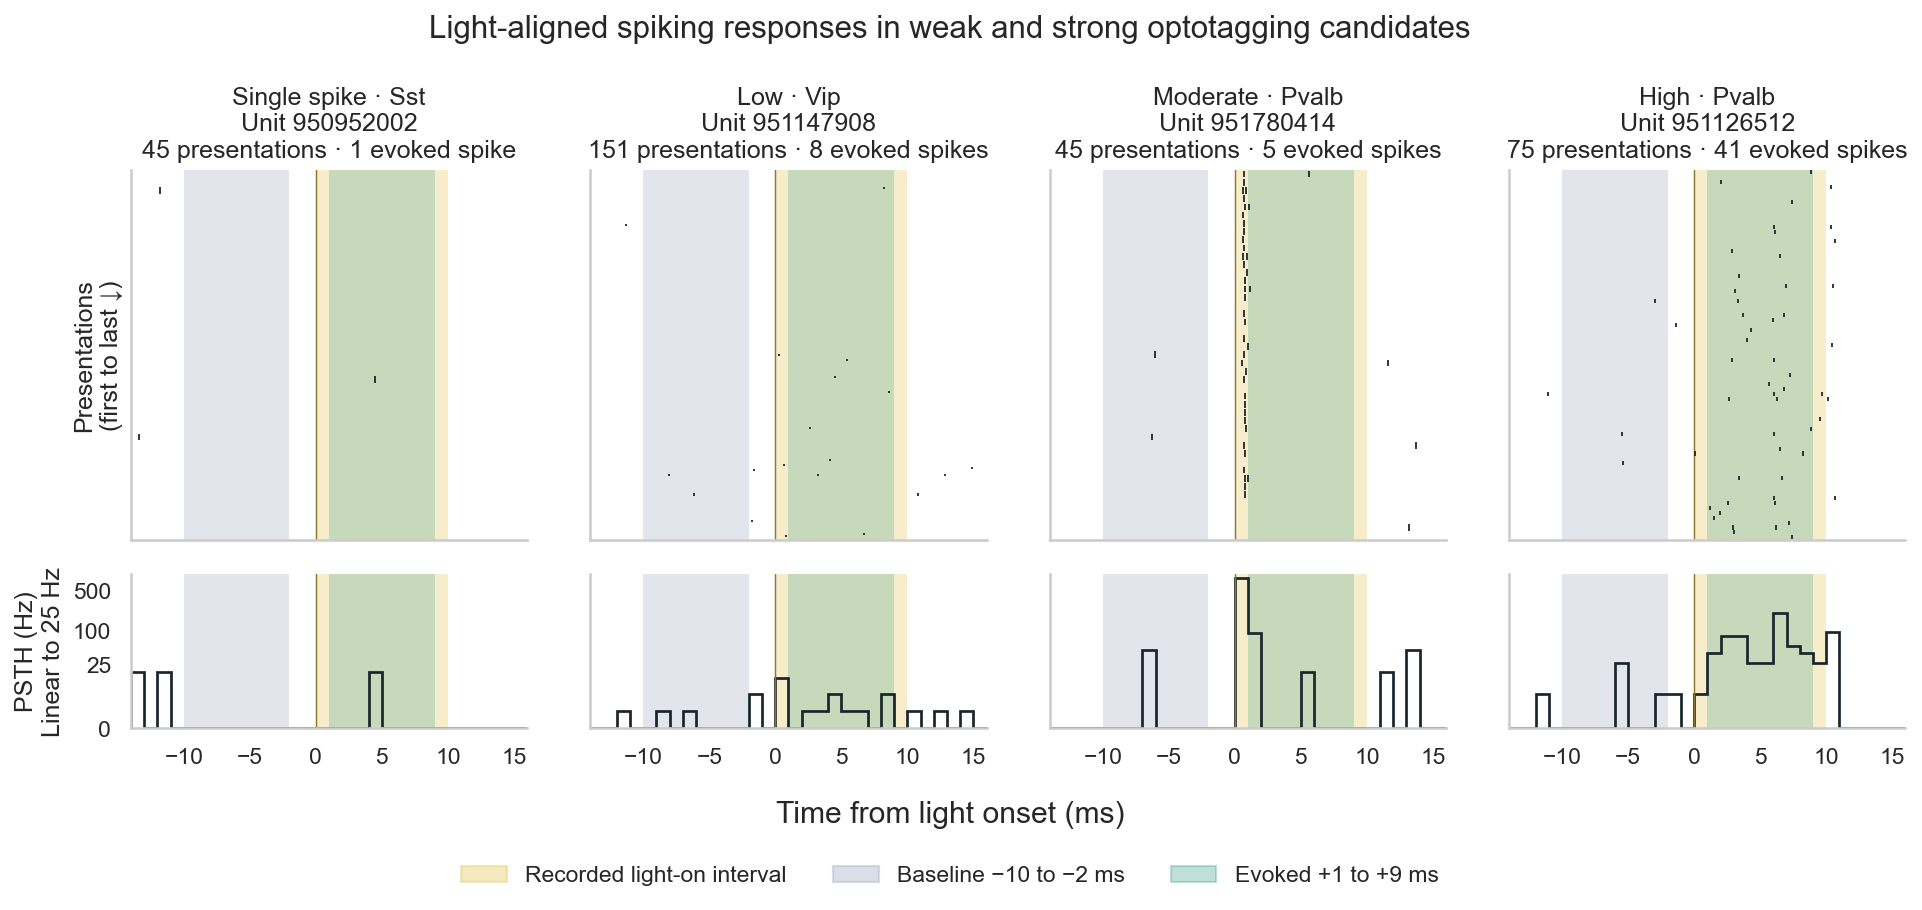

In [4]:
from matplotlib.patches import Patch

opto_light_color, opto_baseline_color, opto_evoked_color = "#e8ca62", "#9fabc0", "#55ae95"
opto_bins_ms = np.arange(-14, 17, 1)
opto_fig, opto_axes = plt.subplots(
    2, len(opto_sample), figsize=(13, 6.1), sharex=True, sharey="row",
    squeeze=False, gridspec_kw={"height_ratios": [2.4, 1]}, dpi=150,
)
opto_peak_hz = 0
for col, (unit_id, row) in enumerate(opto_sample.iterrows()):
    raster_ax, psth_ax = opto_axes[:, col]
    trials = opto_trials_by_unit[unit_id]
    relative_spikes = opto_rasters[unit_id]
    n = len(trials)
    # x uses elapsed milliseconds. y uses a fraction of the raster height.
    durations_ms = 1000 * (trials.stop_time - trials.start_time).to_numpy()
    for y, duration in enumerate(durations_ms):
        raster_ax.axvspan(0, duration, ymin=y / n, ymax=(y + 1) / n,
                         color=opto_light_color, alpha=.33, linewidth=0, zorder=0)
    psth_ax.axvspan(0, durations_ms.min(), color=opto_light_color, alpha=.33, linewidth=0)
    if np.ptp(durations_ms) > 0.001:
        psth_ax.axvspan(durations_ms.min(), durations_ms.max(),
                       color=opto_light_color, alpha=.16, linewidth=0)
    for ax in (raster_ax, psth_ax):
        for window, shade in [(opto_baseline, opto_baseline_color), (opto_evoked, opto_evoked_color)]:
            ax.axvspan(*(1000 * np.array(window)), color=shade, alpha=.30, linewidth=0)
        ax.axvline(0, color="#8e7730", lw=.7)
        ax.set_xlim(opto_bins_ms[[0, -1]])
        ax.set_xticks([-10, -5, 0, 5, 10, 15])
        ax.grid(False)
    raster_ax.eventplot(relative_spikes, lineoffsets=(np.arange(n) + .5) / n,
                        linelengths=.82 / n, linewidths=.85, colors="#18252c")
    evoked_total = trials.evoked.sum()
    spike_label = "spike" if evoked_total == 1 else "spikes"
    raster_ax.set(ylim=(1, 0),
                  title=f"{row.band} · {row.cre_line}\nUnit {unit_id}\n"
                        f"{n} presentations · {evoked_total} evoked {spike_label}")
    raster_ax.set_yticks([])
    spike_hist = np.histogram(np.concatenate(relative_spikes), bins=opto_bins_ms)[0]
    rates_hz = spike_hist / (n * .001)
    psth_ax.stairs(rates_hz, opto_bins_ms, color="#18252c", linewidth=1.3)
    opto_peak_hz = max(opto_peak_hz, rates_hz.max())

# Keep low-count examples visible on the same scale as the onset transient.
opto_psth_axis = opto_axes[1, 0]
opto_psth_axis.set_yscale("symlog", linthresh=25)
opto_psth_axis.set_yticks([0, 25, 100, 500], labels=["0", "25", "100", "500"])
opto_psth_axis.set_ylim(0, max(28, 1.20 * opto_peak_hz))

opto_axes[0, 0].set_ylabel("Presentations\n(first to last ↓)")
opto_axes[1, 0].set_ylabel("PSTH (Hz)\nLinear to 25 Hz")
opto_fig.supxlabel("Time from light onset (ms)", y=.09)
opto_fig.suptitle("Light-aligned spiking responses in weak and strong optotagging candidates",
                  fontsize=15, y=.98)
opto_fig.legend(
    handles=[Patch(color=opto_light_color, alpha=.40, label="Recorded light-on interval"),
             Patch(color=opto_baseline_color, alpha=.38, label="Baseline −10 to −2 ms"),
             Patch(color=opto_evoked_color, alpha=.38, label="Evoked +1 to +9 ms")],
    loc="lower center", bbox_to_anchor=(.5, .005), frameon=False, ncol=3,
)
sns.despine(fig=opto_fig)
opto_fig.subplots_adjust(left=.08, right=.99, top=.81, bottom=.20, wspace=.16, hspace=.13)
plt.show()

**Observed.** The single-spike Sst candidate fired on 1 of 45 trials (2.2%) and had two spikes in the earlier light-off control. The low-response Vip candidate fired on 8 of 151 trials (5.3%) at dispersed latencies, with spikes on 2 baseline trials and 5 earlier control trials. These examples show little repeatable light locking. The moderate Pvalb candidate fired in the evoked window on 5 of 45 trials (11.1%). Its 36 detections within ±1 ms of onset and the drop from five evoked spikes to one in the +2 to +8 ms window make it sensitive to the onset boundary.

The high-response Pvalb candidate fired on 35 of 75 trials (46.7%) versus 3 of 75 at baseline, with a median first-spike latency of 5.64 ms and a median absolute deviation of 1.97 ms. It had nine detections within ±1 ms of offset and still fired on 29 trials (38.7%) in the +2 to +8 ms window. Central-window reliability varied by candidate, and the high candidate's original-window reliability was 7/25 at the lowest recorded level and 14/25 at each higher level.

**For discussion.** One evoked spike supplies too little evidence of reproducible tagging. The moderate example also shows why short latency and low jitter near onset need an artifact check. Before setting a threshold, establish which edge exclusions and light levels to use, check whether the response replicates against matched light-off periods, and agree on a minimum trial response and latency criterion for this protocol. [Published criteria and open questions](LITERATURE_REVIEW.md#1-what-counts-as-optotagged)

In [5]:
opto_reliability_rows = []
for unit_id, row in opto_sample.iterrows():
    trials = opto_trials_by_unit[unit_id]
    n = len(trials)
    evoked, baseline = trials.evoked, trials.baseline
    first_spikes = trials.first_evoked_ms.dropna()
    # Require at least five responding presentations for both descriptive timing summaries.
    latency = first_spikes.median() if len(first_spikes) >= 5 else np.nan
    jitter = (first_spikes - latency).abs().median() if len(first_spikes) >= 5 else np.nan
    opto_reliability_rows.append({
        "Band": row.band, "Unit": unit_id, "Session": row.ecephys_session_id,
        "Cre": row.cre_line, "Period": row.hardware, "Pulses": n,
        "Evoked spike trials": int(evoked.gt(0).sum()),
        "Baseline spike trials": int(baseline.gt(0).sum()),
        "Evoked %": 100 * evoked.gt(0).mean(), "Baseline %": 100 * baseline.gt(0).mean(),
        "Evoked spikes": int(evoked.sum()), "Baseline spikes": int(baseline.sum()),
        "Evoked Hz": evoked.sum() / (n * opto_width_s),
        "Baseline Hz": baseline.sum() / (n * opto_width_s),
        "Latency (ms)": latency, "Jitter (ms)": jitter,
    })

opto_reliability = pd.DataFrame(opto_reliability_rows).set_index("Band")
opto_display = opto_reliability.copy()
for window in ("Evoked", "Baseline"):
    opto_display[f"{window} trials"] = [
        f"{count} ({pct:.1f}%)"
        for count, pct in zip(opto_display.pop(f"{window} spike trials"),
                              opto_display.pop(f"{window} %"))
    ]
display(opto_display[["Unit", "Session", "Cre", "Period", "Pulses", "Evoked trials",
                      "Baseline trials", "Evoked spikes", "Baseline spikes",
                      "Evoked Hz", "Baseline Hz", "Latency (ms)", "Jitter (ms)"]]
        .style.format({col: "{:.2f}" for col in ["Evoked Hz", "Baseline Hz",
                                                 "Latency (ms)", "Jitter (ms)"]}, na_rep="—"))

,Unit,Session,Cre,Period,Pulses,Evoked trials,Baseline trials,Evoked spikes,Baseline spikes,Evoked Hz,Baseline Hz,Latency (ms),Jitter (ms)
Band,,,,,,,,,,,,,
Single spike,950952002,715093703,Sst,LED,45,1 (2.2%),0 (0.0%),1,0,2.78,0.00,—,—
Low,951147908,816200189,Vip,Laser,151,8 (5.3%),2 (1.3%),8,2,6.62,1.66,4.96,1.76
Moderate,951780414,773418906,Pvalb,LED,45,5 (11.1%),2 (4.4%),5,2,13.89,5.56,1.08,0.05
High,951126512,839557629,Pvalb,Laser,75,35 (46.7%),3 (4.0%),41,3,68.33,5.00,5.64,1.97


**Table.** The trial columns show the count and percentage of presentations with at least one window spike. Rates use total spikes divided by total window exposure. Latency is the median first evoked spike time across responding presentations. Jitter is the median absolute deviation of those latencies. Both timing summaries require at least five responding presentations, a descriptive cutoff used here to limit unstable estimates.

### Statistical validation to discuss with Liz

The four examples had paired light-on minus light-off differences of +2.2, +4.0, +6.7 and +42.7 percentage points in ascending response band. Moving from the earlier light-off control to the original baseline produced differences of −4.4, −2.0, +4.4 and 0.0 percentage points. This gives a sense of how much the sparse examples can vary across two dark windows.

Start with per-presentation spike presence. The paired difference in response probability answers how often the unit fired with light versus without it, while preserving presentation pairing. Compare equal exposures, including equal-width controls for a narrower artifact-trimmed evoked window. If unequal windows are scientifically necessary, use a count model with a log-duration offset and a presentation or block effect. Such a model addresses a rate question and needs checks for overdispersion and dependence.

The exploratory calculation below uses an exact one-sided McNemar test on discordant trial pairs. It conditions on the number of discordant pairs, works with a silent baseline, and gives a single evoked-only pair a nominal value of 0.5. Trial pairs must be independent and the two directions of discordance equally likely under the null. The earlier light-off window provides a check for differences between two pre-light windows. Presentations that cross annotated invalid intervals or fail the optical gap checks are omitted from these paired summaries. Keep condition and chronological block in view when evaluating exchangeability.

The examples were selected using their evoked and baseline responses on these same trials. The nominal values are descriptive benchmarks. For confirmation, predeclare the pulse conditions, edge exclusion and primary endpoint, then test independent presentations with candidate selection frozen. An analysis that reuses these recordings would need a null that preserves temporal structure and light level and repeats selection within the null procedure, or a selection-aware design. Investigate control-window stability, within-session dependence and response latency before interpreting any test. For a fixed family of confirmatory unit-level tests with valid p-values, use Holm correction across the full family. A threshold decision also needs an explicit trial-reliability or effect-size criterion and an assessment of sensitivity to light level and artifact exclusion.

In [6]:
%%capture opto_paired_output
def opto_paired_summary(trials, evoked_col, baseline_col):
    pairs = trials.loc[trials.clean_pair]
    evoked = pairs[evoked_col].gt(0)
    baseline = pairs[baseline_col].gt(0)
    evoked_only = int((evoked & ~baseline).sum())
    baseline_only = int((baseline & ~evoked).sum())
    discordant = evoked_only + baseline_only
    nominal_p = (stats.binomtest(evoked_only, discordant, alternative="greater").pvalue
                 if discordant else 1.0 if len(pairs) else np.nan)
    return {
        "pairs": len(pairs), "first only": evoked_only, "second only": baseline_only,
        "first occupancy %": 100 * evoked.mean(), "second occupancy %": 100 * baseline.mean(),
        "difference (pp)": 100 * (evoked.mean() - baseline.mean()), "nominal p": nominal_p,
    }


opto_paired = pd.DataFrame.from_dict(
    {unit_id: opto_paired_summary(trials, "evoked", "baseline")
     for unit_id, trials in opto_trials_by_unit.items()}, orient="index",
)
opto_dark_control = pd.DataFrame.from_dict(
    {unit_id: opto_paired_summary(trials, "baseline", "earlier_control")
     for unit_id, trials in opto_trials_by_unit.items()}, orient="index",
)
opto_trimmed = pd.DataFrame.from_dict(
    {unit_id: opto_paired_summary(trials, "inner_evoked", "inner_baseline")
     for unit_id, trials in opto_trials_by_unit.items()}, orient="index",
)
display(opto_paired, opto_dark_control, opto_trimmed)

## Waveform morphology across optotagging candidate classes

Do Pvalb, Sst, and Vip optotagging candidates in visual cortex differ in extracellular spike shape? Compare peak-channel mean waveforms from up to 15 candidates per Cre line, sampling up to five units per recording session. The saved `matched_candidate` flag defines provisional candidate membership. Align traces at the negative trough and divide by its magnitude to compare shape across amplitudes.

/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.6.0-alpha is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531

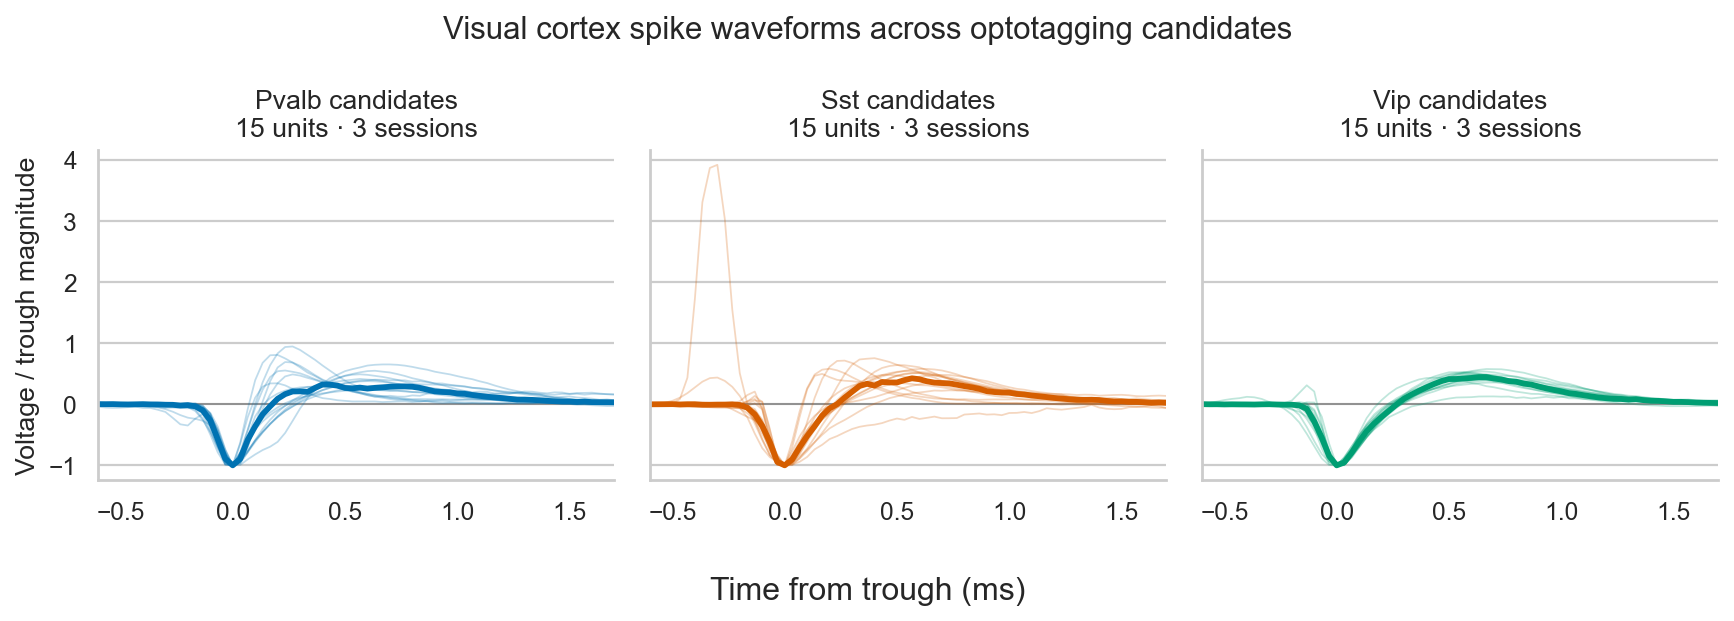

In [11]:
from collections import Counter
from pathlib import Path
import os

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from allensdk.brain_observatory.ecephys.ecephys_session import EcephysSession
from allensdk.brain_observatory.ecephys.ecephys_session_api.ecephys_nwb_session_api import (
    EcephysNwbSessionApi,
)
from pynwb import NWBHDF5IO


def aligned_peak_trace(unit_id, units, waveforms):
    if unit_id not in units.index or unit_id not in waveforms:
        raise ValueError("unit or mean waveform missing")
    peak_channel = units.at[unit_id, "peak_channel_id"]
    try:
        trace = waveforms[unit_id].sel(channel_id=peak_channel)
    except KeyError as exc:
        raise ValueError("peak channel missing") from exc

    voltage = np.asarray(trace.values, dtype=float)
    if "time" not in trace.coords:
        raise ValueError("time coordinates missing")
    time_ms = np.asarray(trace["time"].values, dtype=float) * 1000
    if (voltage.shape != time_ms.shape or voltage.ndim != 1 or voltage.size < 3
            or not np.isfinite(voltage).all() or not np.isfinite(time_ms).all()
            or not (np.diff(time_ms) > 0).all()):
        raise ValueError("invalid voltage or time coordinates")

    trough = int(np.argmin(voltage))
    if trough in (0, voltage.size - 1) or voltage[trough] >= 0:
        raise ValueError("no interior negative trough")
    return time_ms - time_ms[trough], voltage / abs(voltage[trough])


def sample_waveforms(pool, cache_dir, rng, target=15, per_session=5):
    groups = pool.groupby("ecephys_session_id", sort=True)
    sampled, skipped = [], Counter()
    for session_id in rng.permutation(list(groups.groups)):
        nwb_path = cache_dir / f"session_{session_id}" / f"session_{session_id}.nwb"
        if not nwb_path.is_file():
            skipped["session NWB missing"] += 1
            continue

        unit_ids = rng.permutation(np.sort(groups.get_group(session_id)["unit_id"]))
        session_count = 0
        # Buffer one read-only session at a time to avoid repeated reads from the drive.
        try:
            with (h5py.File(nwb_path, "r", driver="core", backing_store=False) as h5,
                  NWBHDF5IO(file=h5, mode="r", load_namespaces=True) as io):
                ecephys = EcephysSession(api=EcephysNwbSessionApi.from_nwbfile(io.read()))
                units, waveforms = ecephys.units, ecephys.mean_waveforms
                for unit_id in unit_ids:
                    try:
                        time_ms, voltage = aligned_peak_trace(unit_id, units, waveforms)
                    except ValueError as exc:
                        skipped[str(exc)] += 1
                        continue
                    sampled.append((session_id, unit_id, time_ms, voltage))
                    session_count += 1
                    if session_count == per_session or len(sampled) == target:
                        break
                del units, waveforms, ecephys
        except OSError as exc:
            skipped["session NWB unreadable"] += 1
            print(f"Session {session_id}: {exc}")
        if len(sampled) == target:
            break
    return sampled, skipped


waveform_root = Path(os.environ.get("SPIKES2SLOPE_DATA", "/Volumes/WD_BLACK/Spikes2Slope"))
opto = pd.read_csv(waveform_root / "opto_results" / "all_opto_unit_results.csv")
matched = opto["matched_candidate"].astype(str).str.strip().str.lower().isin(["true", "1"])
visual_candidates = opto.loc[matched & opto["region"].str.startswith("VIS", na=False)]
waveform_colors = {"Pvalb": "#0072B2", "Sst": "#D55E00", "Vip": "#009E73"}
waveform_rng = np.random.default_rng(42)
waveform_samples = {}
for candidate_class in waveform_colors:
    pool = visual_candidates.loc[visual_candidates["cre_line"].eq(candidate_class)]
    sampled, skipped = sample_waveforms(
        pool, waveform_root / "allen_visual_coding_data", waveform_rng
    )
    waveform_samples[candidate_class] = sampled
    if skipped or len(sampled) < 15:
        print(f"{candidate_class}: {len(sampled)}/15 usable waveforms. Skipped: {dict(skipped)}")

# Use only the time range shared by every trace, with no extrapolation.
aligned_times = [time for rows in waveform_samples.values() for _, _, time, _ in rows]
if not aligned_times:
    raise RuntimeError("No usable visual-cortex waveforms in the local Allen cache.")
left = max(time[0] for time in aligned_times)
right = min(time[-1] for time in aligned_times)
step = max(np.median(np.diff(time)) for time in aligned_times)
grid_ms = step * np.arange(np.ceil(left / step), np.floor(right / step) + 1)
if grid_ms.size < 3:
    raise RuntimeError("Too few shared time samples for waveform comparison.")

sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharex=True, sharey=True, dpi=160)
for ax, (candidate_class, color) in zip(axes, waveform_colors.items()):
    rows = waveform_samples[candidate_class]
    n_sessions = len({session_id for session_id, _, _, _ in rows})
    ax.axhline(0, color="0.55", linewidth=0.8)
    ax.grid(axis="x", visible=False)
    if rows:
        traces = np.array([np.interp(grid_ms, time, voltage) for _, _, time, voltage in rows])
        ax.plot(grid_ms, traces.T, color=color, linewidth=0.8, alpha=0.25)
        ax.plot(grid_ms, np.median(traces, axis=0), color=color, linewidth=2.6)
    else:
        ax.text(0.5, 0.5, "No usable waveforms", ha="center", transform=ax.transAxes)
    session_label = "session" if n_sessions == 1 else "sessions"
    ax.set(title=f"{candidate_class} candidates\n{len(rows)} units · {n_sessions} {session_label}",
           xlim=(grid_ms[0], grid_ms[-1]))

axes[0].set_ylabel("Voltage / trough magnitude")
fig.supxlabel("Time from trough (ms)")
fig.suptitle("Visual cortex spike waveforms across optotagging candidates", fontsize=14)
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

- Pvalb: The median waveform has a relatively rapid recovery after the negative trough, consistent with the shorter-duration waveforms we've previously observed. There's also considerable variability in the positive rebound.
- Sst: The median waveform appears broader, with a later positive peak. One individual waveform has an unusually large positive deflection before the trough, which is worth investigating.
- Vip: The individual waveforms look relatively consistent, with a broad positive rebound and less obvious variability than the other two groups.

**Literature check — can SST and VIP be told apart from waveform features alone?** The [Neuropixels Ultra study](https://pmc.ncbi.nlm.nih.gov/articles/PMC10473688/) reports that genetically identified PV/SST/VIP neurons “could be discriminated with approximately 75% accuracy” using higher-density extracellular recordings (three-class evaluation). **This does not establish reliable SST-vs-VIP binary discrimination with our three waveform summary features or older Neuropixels probes; nor does it prove discrimination is impossible.** In this notebook, SST and VIP candidate waveforms overlap substantially. **For Liz:** Waveform duration is not biological ground truth. Validate optotagging labels first; then test a held-out SST-vs-VIP classifier using waveform, ISI/bursting, and other features with session/animal-aware splits.

Kilosort2 sorts spikes into units. We separately fit two- and three-group K-means models to the same QC-passing visual-cortex units from 28 recordings. Both fits use log-transformed, standardized waveform duration, half-width, and peak-to-trough ratio. Candidate labels play no role in fitting.

The three-group fit had the higher silhouette score among the two tested fits, so its waveforms are shown below. Panel counts describe the clustered population. Each panel displays 16 sampled waveforms from four shared sessions. Both fits are examined in the candidate comparison that follows.

/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.6.0-alpha is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531

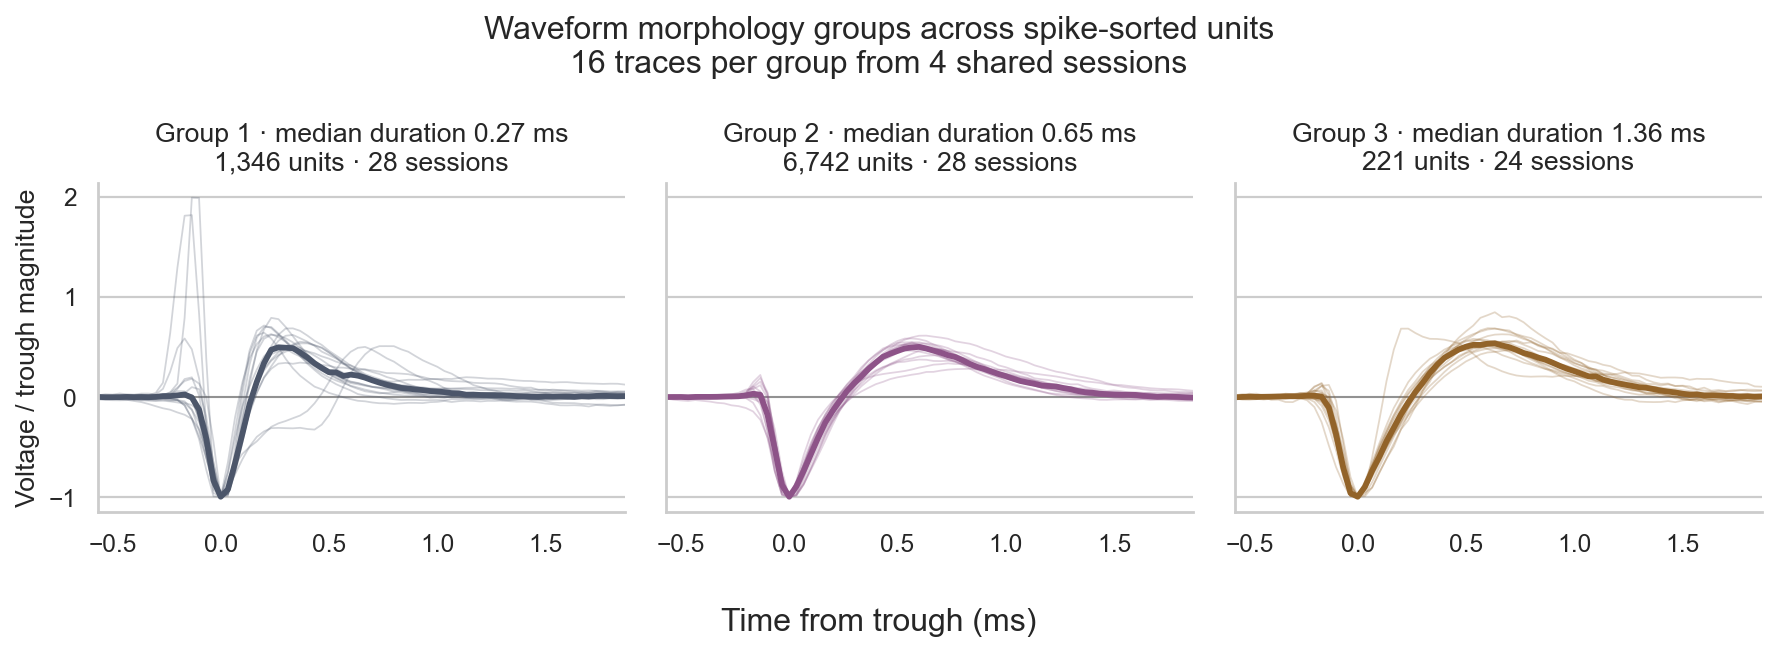

Clustered 8,309/8,385 QC visual-cortex units from 28 sessions. Silhouette: k=2 0.489, k=3 0.533.
Saved assignments to /Volumes/WD_BLACK/Spikes2Slope/opto_results/kilosort_waveform_groups.csv


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

results_path = waveform_root / "opto_results"
morphology_features = ["waveform_duration", "waveform_halfwidth", "waveform_PT_ratio"]
unit_features = pd.read_csv(results_path / "master_waveform_features.csv")
qc_visual = unit_features.loc[
    unit_features["ecephys_session_id"].isin(opto["ecephys_session_id"])
    & unit_features["ecephys_structure_acronym"].str.startswith("VIS", na=False)
    & unit_features["presence_ratio"].ge(.95)
    & unit_features["isi_violations"].le(.5)
    & unit_features["amplitude_cutoff"].le(.1)
    & unit_features["snr"].ge(1),
    ["unit_id", "ecephys_session_id", "ecephys_structure_acronym", *morphology_features],
].sort_values("unit_id")

features = qc_visual[morphology_features]
usable_features = np.isfinite(features).all(axis=1) & features.gt(0).all(axis=1)
waveform_groups = qc_visual.loc[usable_features].copy()
assert waveform_groups["unit_id"].is_unique
scaled_features = StandardScaler().fit_transform(np.log(waveform_groups[morphology_features]))

group_labels, scores = {}, {}
with threadpool_limits(limits=1):
    for k in (2, 3):
        labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(scaled_features)
        group_labels[k] = labels
        scores[k] = silhouette_score(scaled_features, labels, sample_size=min(2500, len(labels)),
                                     random_state=42)
chosen_k = max(scores, key=scores.get)
duration_order = (waveform_groups.groupby(group_labels[chosen_k])["waveform_duration"]
                  .median().sort_values().index)
waveform_groups["waveform_group"] = pd.Series(group_labels[chosen_k], index=waveform_groups.index).map(
    {label: number for number, label in enumerate(duration_order, start=1)}
)
group_summary = waveform_groups.groupby("waveform_group").agg(
    units=("unit_id", "size"), sessions=("ecephys_session_id", "nunique"),
    duration_ms=("waveform_duration", "median"),
)

# Draw the same recordings for all panels, with four traces per session and group.
group_rng = np.random.default_rng(42)
session_coverage = pd.crosstab(waveform_groups["ecephys_session_id"], waveform_groups["waveform_group"])
eligible_sessions = session_coverage.index[session_coverage.ge(4).all(axis=1)]
group_traces = {group: [] for group in group_summary.index}
sampled_unit_ids = set()
plotted_sessions = []
skipped_traces = Counter()
for sid in group_rng.permutation(eligible_sessions):
    nwb_path = waveform_root / "allen_visual_coding_data" / f"session_{sid}" / f"session_{sid}.nwb"
    if not nwb_path.is_file():
        skipped_traces["missing cached session"] += 1
        continue
    rows = waveform_groups.loc[waveform_groups["ecephys_session_id"].eq(sid)]
    session_traces = {group: [] for group in group_traces}
    try:
        with (h5py.File(nwb_path, "r", driver="core", backing_store=False) as h5,
              NWBHDF5IO(file=h5, mode="r", load_namespaces=True) as io):
            ecephys = EcephysSession(api=EcephysNwbSessionApi.from_nwbfile(io.read()))
            units, waveforms = ecephys.units, ecephys.mean_waveforms
            for group, pool in rows.groupby("waveform_group"):
                for uid in group_rng.permutation(pool["unit_id"].to_numpy()):
                    try:
                        time_ms, voltage = aligned_peak_trace(uid, units, waveforms)
                    except ValueError as exc:
                        skipped_traces[str(exc)] += 1
                        continue
                    session_traces[group].append((uid, time_ms, voltage))
                    if len(session_traces[group]) == 4:
                        break
            del units, waveforms, ecephys
    except OSError:
        skipped_traces["unreadable cached session"] += 1
        continue
    if any(len(traces) < 4 for traces in session_traces.values()):
        skipped_traces["session without four valid traces per group"] += 1
        continue
    for group, traces in session_traces.items():
        group_traces[group].extend((time_ms, voltage) for _, time_ms, voltage in traces)
        sampled_unit_ids.update(uid for uid, _, _ in traces)
    plotted_sessions.append(sid)
    if len(plotted_sessions) == 4:
        break

if len(plotted_sessions) < 2:
    raise RuntimeError("Fewer than two cached sessions have enough usable waveforms in every group.")

# Interpolate over shared time support, with a grid point at the negative trough.
group_times = [time for traces in group_traces.values() for time, _ in traces]
left = max(t[0] for t in group_times)
right = min(t[-1] for t in group_times)
step = max(np.median(np.diff(t)) for t in group_times)
group_grid_ms = step * np.arange(np.ceil(left / step), np.floor(right / step) + 1)
if group_grid_ms.size < 3:
    raise RuntimeError("Too few shared time samples for waveform comparison.")

sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(1, chosen_k, figsize=(3.8 * chosen_k, 4), sharex=True, sharey=True, dpi=160)
for ax, (group, summary), color in zip(axes, group_summary.iterrows(), ["#4C566A", "#8D5388", "#926329"]):
    traces = np.array([np.interp(group_grid_ms, t, v) for t, v in group_traces[group]])
    ax.axhline(0, color="0.55", linewidth=.8)
    ax.grid(axis="x", visible=False)
    ax.plot(group_grid_ms, traces.T, color=color, linewidth=.8, alpha=.25)
    ax.plot(group_grid_ms, np.median(traces, axis=0), color=color, linewidth=2.6)
    ax.set(title=f"Group {group} · median duration {summary.duration_ms:.2f} ms\n"
           f"{int(summary.units):,} units · {int(summary.sessions)} sessions",
           xlim=(group_grid_ms[0], group_grid_ms[-1]))

axes[0].set_ylabel("Voltage / trough magnitude")
fig.supxlabel("Time from trough (ms)")
fig.suptitle(f"Waveform morphology groups across spike-sorted units\n"
             f"{len(group_traces[1])} traces per group from {len(plotted_sessions)} shared sessions")
sns.despine(fig=fig)
fig.tight_layout()
plt.show()

waveform_groups["plotted"] = waveform_groups["unit_id"].isin(sampled_unit_ids)
assignment_path = results_path / "kilosort_waveform_groups.csv"
waveform_groups.to_csv(assignment_path, index=False)
print(f"Clustered {len(waveform_groups):,}/{len(qc_visual):,} QC visual-cortex units "
      f"from {waveform_groups.ecephys_session_id.nunique()} sessions. "
      f"Silhouette: k=2 {scores[2]:.3f}, k=3 {scores[3]:.3f}.")
if skipped_traces:
    print(f"Skipped during waveform sampling: {dict(skipped_traces)}")
print(f"Saved assignments to {assignment_path}")

### Optotagging candidate composition within waveform groups

Where do optotagging candidates fall within the full waveform clusters? Each bar represents all units in one group, with matched Pvalb, Sst, and Vip candidates highlighted by color. Gray represents the remaining clustered units. Group numbers follow median waveform duration within each fit.

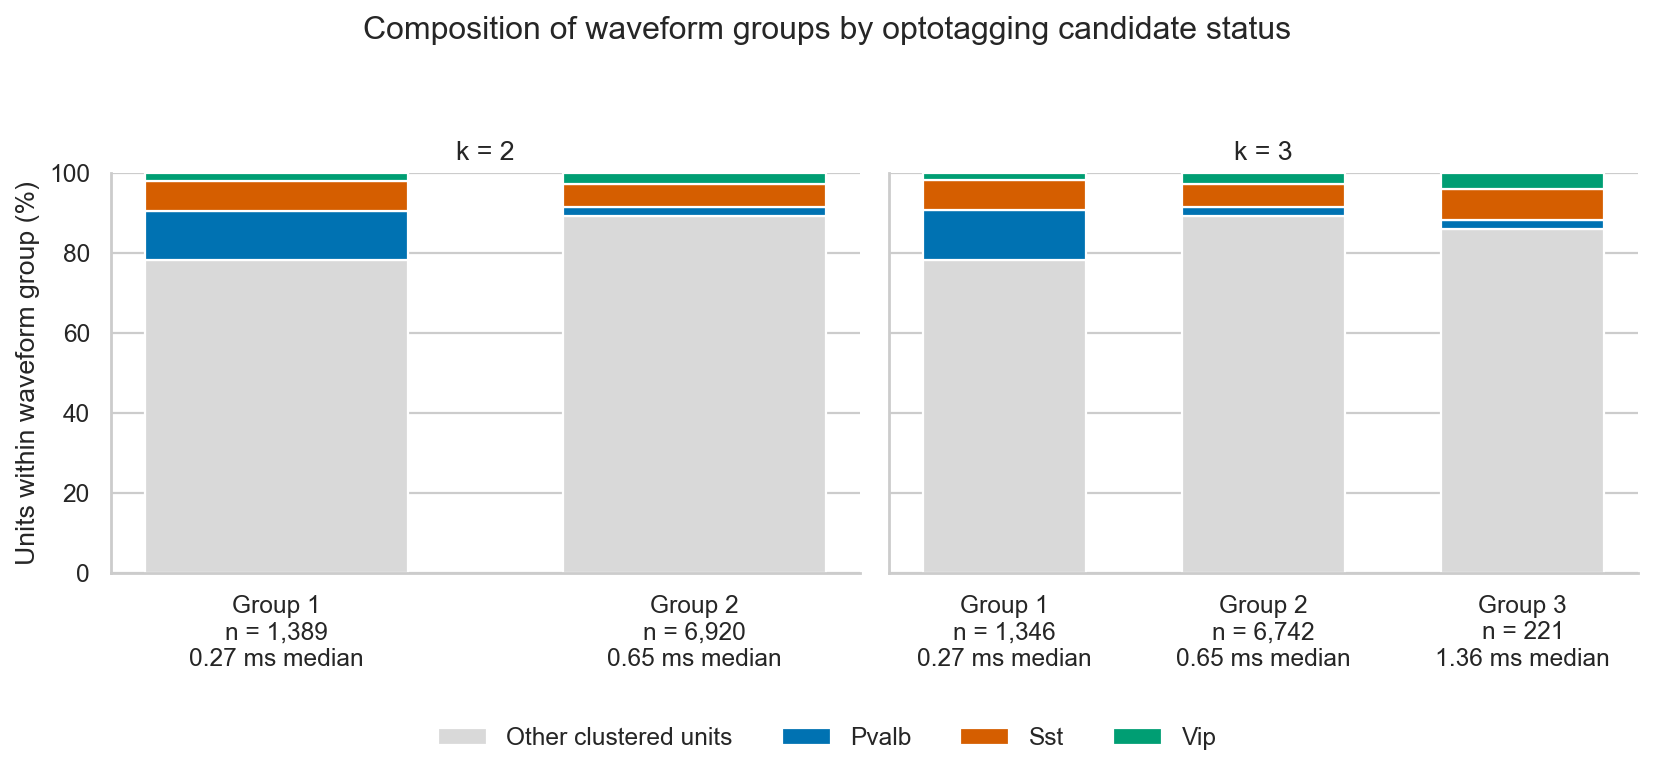

Matched 1,054 of 1,127 optotagging candidates. Excluded 73.
Outside visual cortex                  59
Missing or invalid waveform feature    14

Composition by waveform group
         Total  Median (ms)  Matched  Matched (%)  Pvalb  Sst  Vip
k Group                                                           
2 1       1389         0.27      301        21.67    170  104   27
  2       6920         0.65      753        10.88    162  396  195
3 1       1346         0.27      292        21.69    168  101   23
  2       6742         0.65      731        10.84    159  382  190
  3        221         1.36       31        14.03      5   17    9


In [13]:
# Reuse the two independently fitted models from the waveform cell above.
assignments_both = waveform_groups[["unit_id", "ecephys_session_id", "waveform_duration"]].copy()
group_columns = {k: f"waveform_group_k{k}" for k in (2, 3)}
for k, column in group_columns.items():
    medians = assignments_both.groupby(group_labels[k])["waveform_duration"].median()
    ordered = medians.sort_values().index
    assignments_both[column] = pd.Series(group_labels[k], index=assignments_both.index).map(
        {label: rank for rank, label in enumerate(ordered, start=1)}
    )

saved_k3 = pd.read_csv(results_path / "kilosort_waveform_groups.csv")
pd.testing.assert_frame_equal(
    assignments_both[["unit_id", "ecephys_session_id", "waveform_group_k3"]]
    .sort_values("unit_id").reset_index(drop=True),
    saved_k3[["unit_id", "ecephys_session_id", "waveform_group"]]
    .rename(columns={"waveform_group": "waveform_group_k3"})
    .sort_values("unit_id").reset_index(drop=True),
)

saved_both = pd.read_csv(results_path / "kilosort_waveform_groups_k2_k3.csv")
pd.testing.assert_frame_equal(
    assignments_both.drop(columns="waveform_duration").sort_values("unit_id").reset_index(drop=True),
    saved_both.sort_values("unit_id").reset_index(drop=True),
)

cre_lines = ["Pvalb", "Sst", "Vip"]
assert opto["unit_id"].notna().all() and assignments_both["unit_id"].notna().all()
joined = opto.merge(
    assignments_both.drop(columns="waveform_duration"), on="unit_id", how="left",
    validate="one_to_one", indicator=True, suffixes=("", "_assignment"),
)
assigned = joined["_merge"].eq("both")
assert joined.loc[assigned, "ecephys_session_id"].eq(
    joined.loc[assigned, "ecephys_session_id_assignment"]
).all()

candidate_flag = joined["matched_candidate"].astype(str).str.strip().str.lower().isin(["true", "1"])
valid_line = joined["cre_line"].isin(cre_lines)
matched_candidates = joined.loc[candidate_flag & valid_line & assigned].copy()
excluded = joined.loc[candidate_flag & ~(valid_line & assigned)].copy()
audit = unit_features.set_index("unit_id", verify_integrity=True)
region = excluded["unit_id"].map(audit["ecephys_structure_acronym"]).fillna(excluded["region"])
in_visual = region.str.startswith("VIS", na=False)
in_qc = excluded["unit_id"].isin(qc_visual["unit_id"])
in_features = excluded["unit_id"].isin(unit_features["unit_id"])
exclusion_reasons = np.select(
    [~excluded["cre_line"].isin(cre_lines), ~in_visual, in_qc, ~in_features],
    ["Cre line outside comparison", "Outside visual cortex", "Missing or invalid waveform feature",
     "Missing from saved feature table"],
    default="Outside the clustering QC population",
)
assert len(matched_candidates) + len(excluded) == candidate_flag.sum()

category_colors = {"Other clustered units": "#D9D9D9",
                   "Pvalb": "#0072B2", "Sst": "#D55E00", "Vip": "#009E73"}
summary_rows = []
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), sharey=True, dpi=160)

for ax, (k, column) in zip(axes, group_columns.items()):
    full = assignments_both.groupby(column).agg(
        total=("unit_id", "size"),
        median_ms=("waveform_duration", "median"),
    )
    counts = pd.crosstab(matched_candidates[column], matched_candidates["cre_line"]).reindex(
        index=full.index, columns=cre_lines, fill_value=0
    )
    full["matched"] = counts.sum(axis=1)
    full["matched_pct"] = full["matched"].div(full["total"]).mul(100)
    counts["Other clustered units"] = full["total"] - full["matched"]
    assert counts["Other clustered units"].ge(0).all()
    assert full["matched"].sum() == len(matched_candidates)
    assert full["total"].sum() == len(assignments_both)
    percentages = counts.div(full["total"], axis=0).mul(100)
    assert np.allclose(percentages.sum(axis=1), 100)

    x = np.arange(len(full))
    bottom = np.zeros(len(full))
    for category, color in category_colors.items():
        heights = percentages[category].to_numpy()
        ax.bar(x, heights, bottom=bottom, width=.63, color=color, label=category)
        bottom += heights
    ax.set_xticks(x, [f"Group {group}\nn = {row.total:,.0f}\n{row.median_ms:.2f} ms median"
                      for group, row in full.iterrows()])
    ax.set(title=f"k = {k}", ylim=(0, 100))
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    summary_rows.append(full.join(counts[cre_lines]).rename_axis("Group"))

axes[0].set_ylabel("Units within waveform group (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Composition of waveform groups by optotagging candidate status")
sns.despine(fig=fig)
fig.tight_layout(rect=(0, .09, 1, .93))
plt.show()

print(f"Matched {len(matched_candidates):,} of {candidate_flag.sum():,} optotagging candidates. "
      f"Excluded {len(excluded):,}.")
print(pd.Series(exclusion_reasons).value_counts().rename("Excluded").to_string())
cluster_composition = pd.concat(summary_rows, keys=group_columns, names=["k", "Group"])
print("\nComposition by waveform group")
print(cluster_composition.rename(columns={"total": "Total", "median_ms": "Median (ms)",
                                          "matched": "Matched", "matched_pct": "Matched (%)"})
      .round(2).to_string())

**Reading the cluster composition**
This cluster-centric view uses all units in each waveform group as the denominator. The previous candidate-centric view used each Cre-line candidate population as the denominator. In both fits, shorter-duration Group 1 had the highest share of matched candidates (about **21.7%**) and of Pvalb candidates (about **12%** of the cluster, versus roughly **2.3%** in the other groups). The larger Group 2 contained the most matched candidates by count.

Other units made up **78–89%** of each bar, as expected when clustering all eligible QC-passing units. These pooled differences may reflect recording-session or stimulation-protocol differences. The candidate labels remain provisional, and the waveform groups provide no independent confirmation of biological identity.